# Part-to-whole and hierarchical charts

Stacks, waffles and icon arrays; pies done carefully; Marimekko and mosaic; treemaps in three geometries (squarified, circle-packed, convex polygons); sets; gauges; funnels.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import pandas as pd
import pychartist as pc
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # renders in JupyterLab/VS Code/Colab; plotly.js from CDN

In [2]:
titanic = pc.datasets.load('titanic'); g07 = pc.datasets.load('gapminder').query('year == 2007')

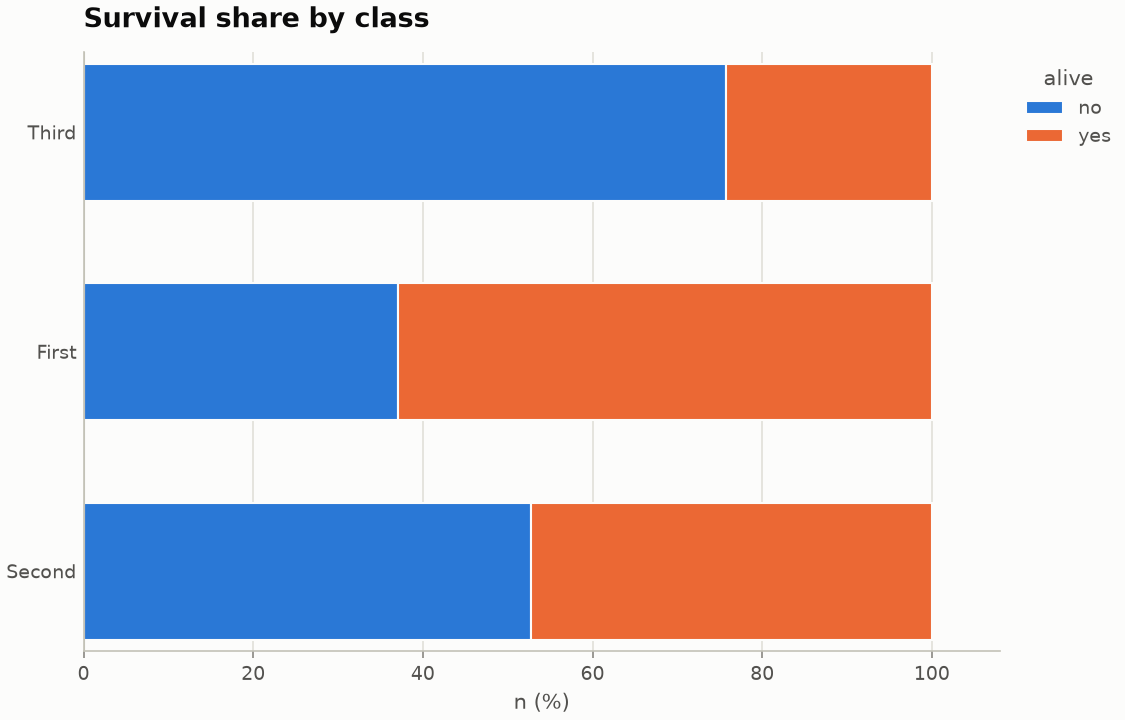

In [3]:
pc.stacked_bar(titanic.assign(n=1), 'class', 'n', 'alive', normalize=True, orient='h',
               title='Survival share by class')

In [4]:
pc.examples.demo('diverging_bar', backend='plotly')

<Chart kind='diverging_bar' backend='plotly' theme='pychartist'>

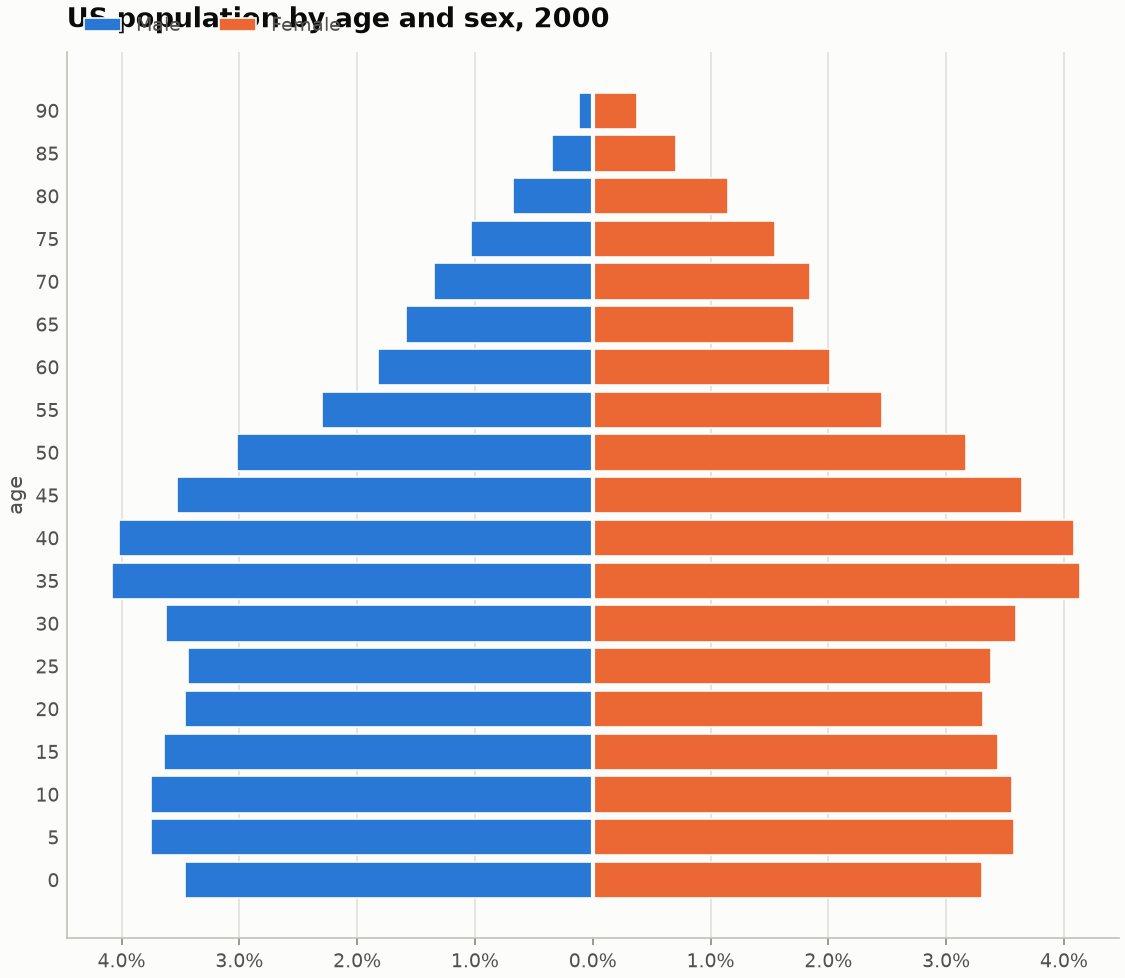

In [5]:
pc.examples.demo('population_pyramid')

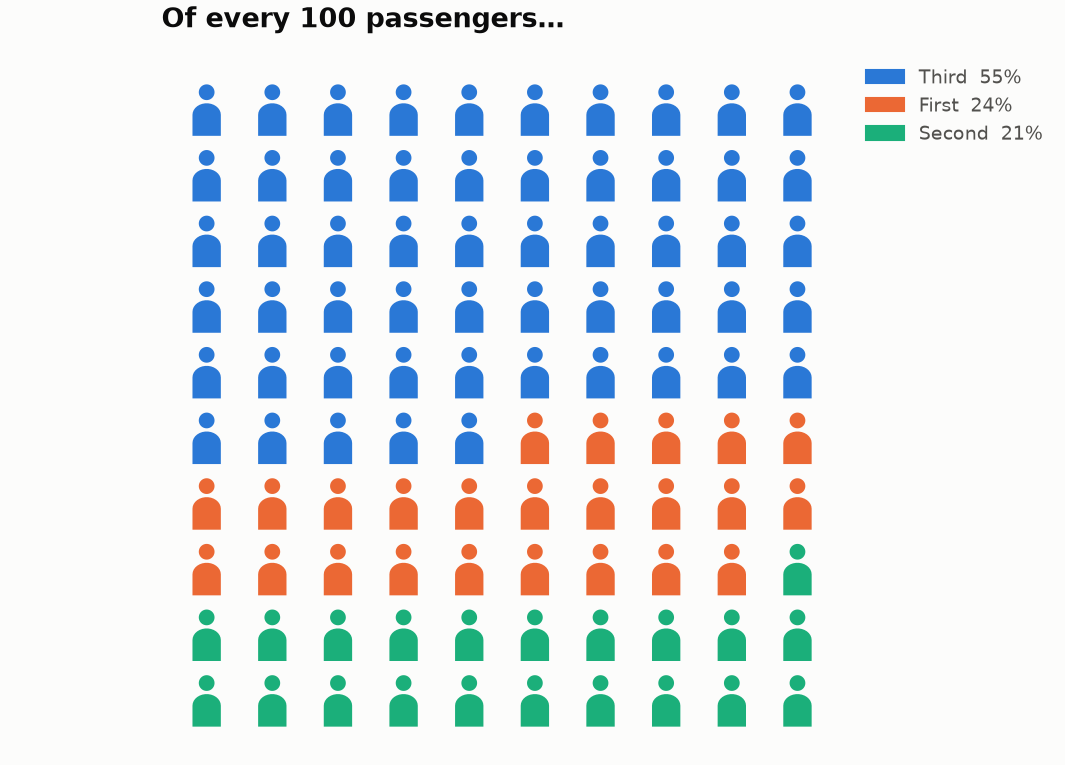

In [6]:
pc.icon_array(titanic, 'class', title='Of every 100 passengers…')

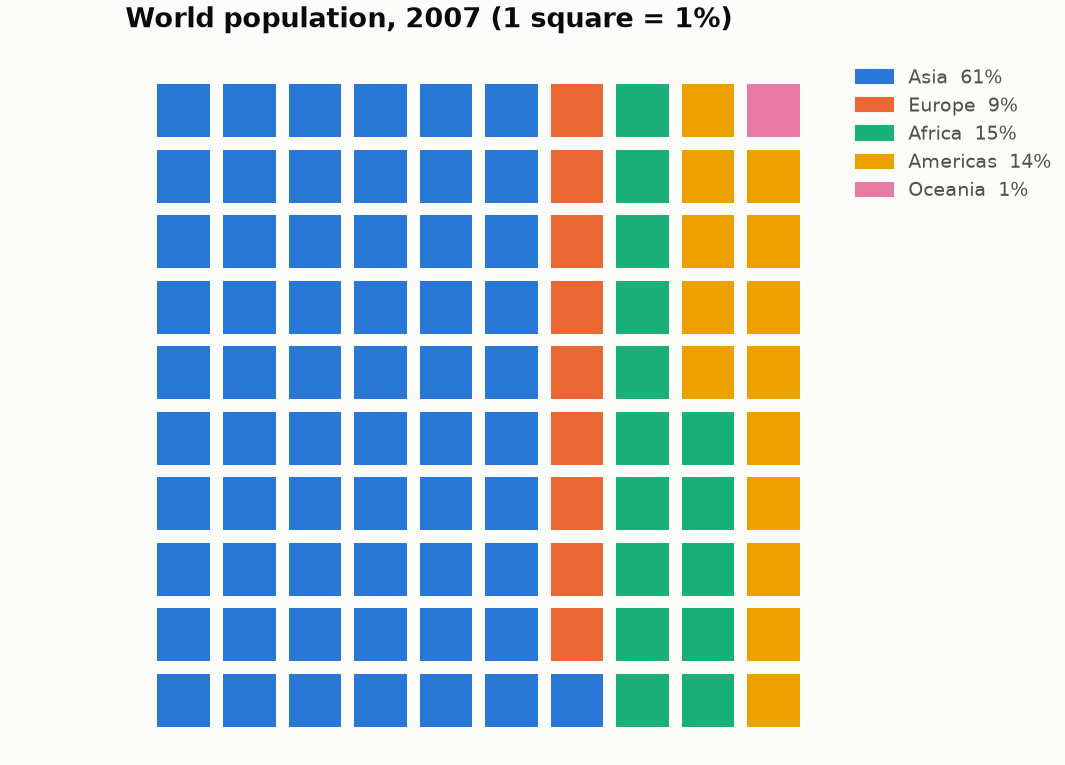

In [7]:
pc.waffle(g07, 'continent', 'pop', title='World population, 2007 (1 square = 1%)')

In [8]:
pc.donut(g07, 'continent', 'pop', backend='plotly')

<Chart kind='donut' backend='plotly' theme='pychartist'>

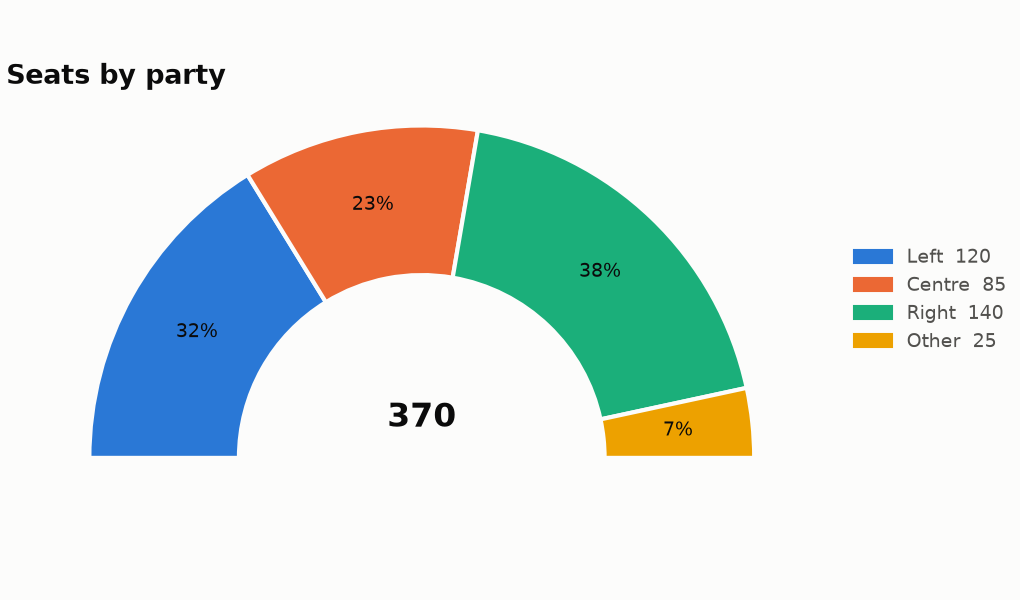

In [9]:
pc.examples.demo('semicircle_donut')

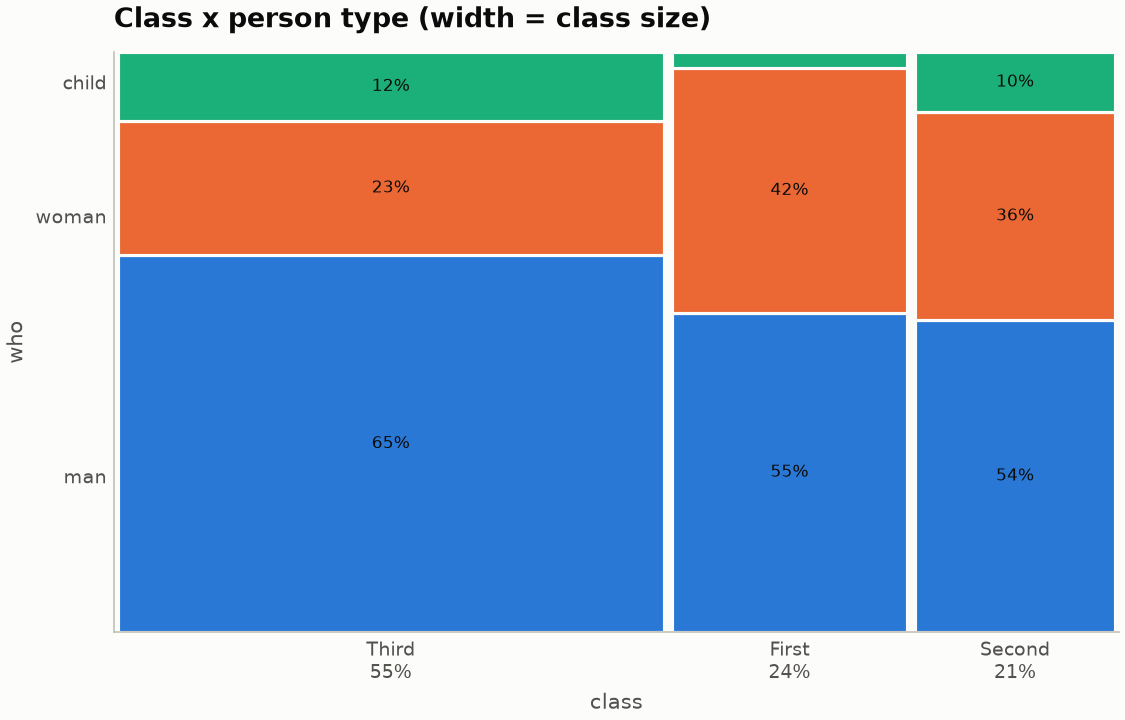

In [10]:
pc.marimekko(titanic, 'class', 'who', title='Class x person type (width = class size)')

{'statistic': 102.88898875696057, 'pvalue': 4.5492517112987287e-23, 'dof': 2}


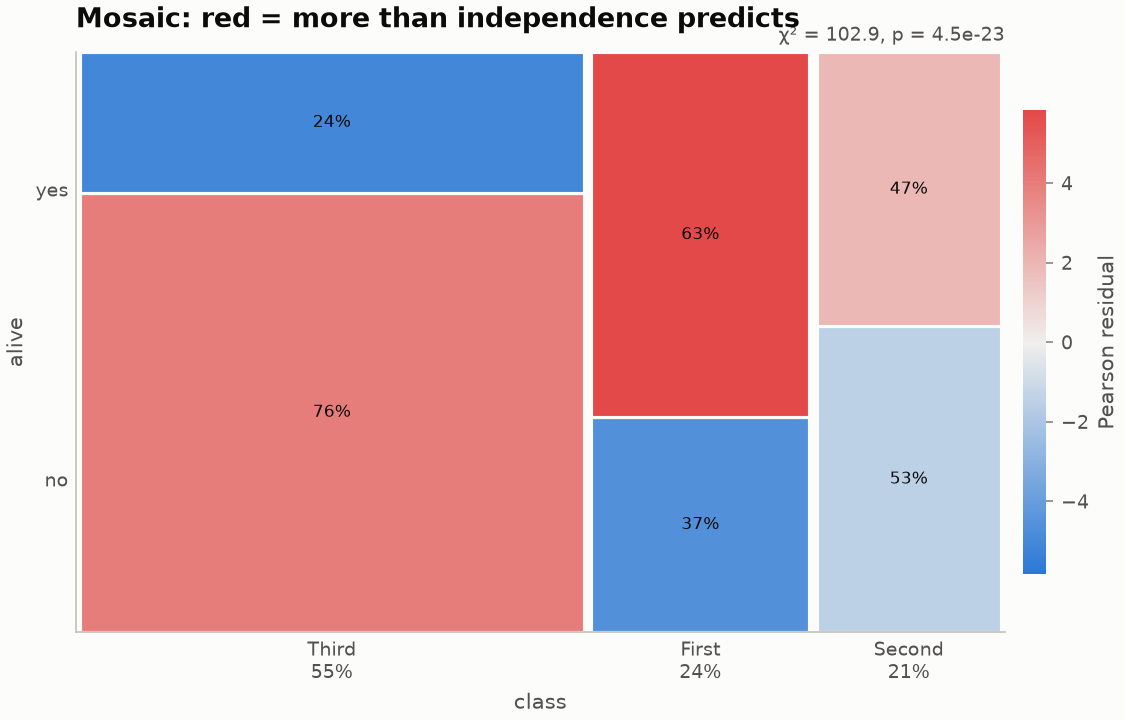

In [11]:
c = pc.mosaic(titanic, 'class', 'alive', title='Mosaic: red = more than independence predicts')
print(c.meta['chi2'])
c

## Three treemap geometries

In [12]:
pc.treemap(g07, ['continent', 'country'], 'pop', backend='plotly', title='Click to zoom')

<Chart kind='treemap' backend='plotly' theme='pychartist'>

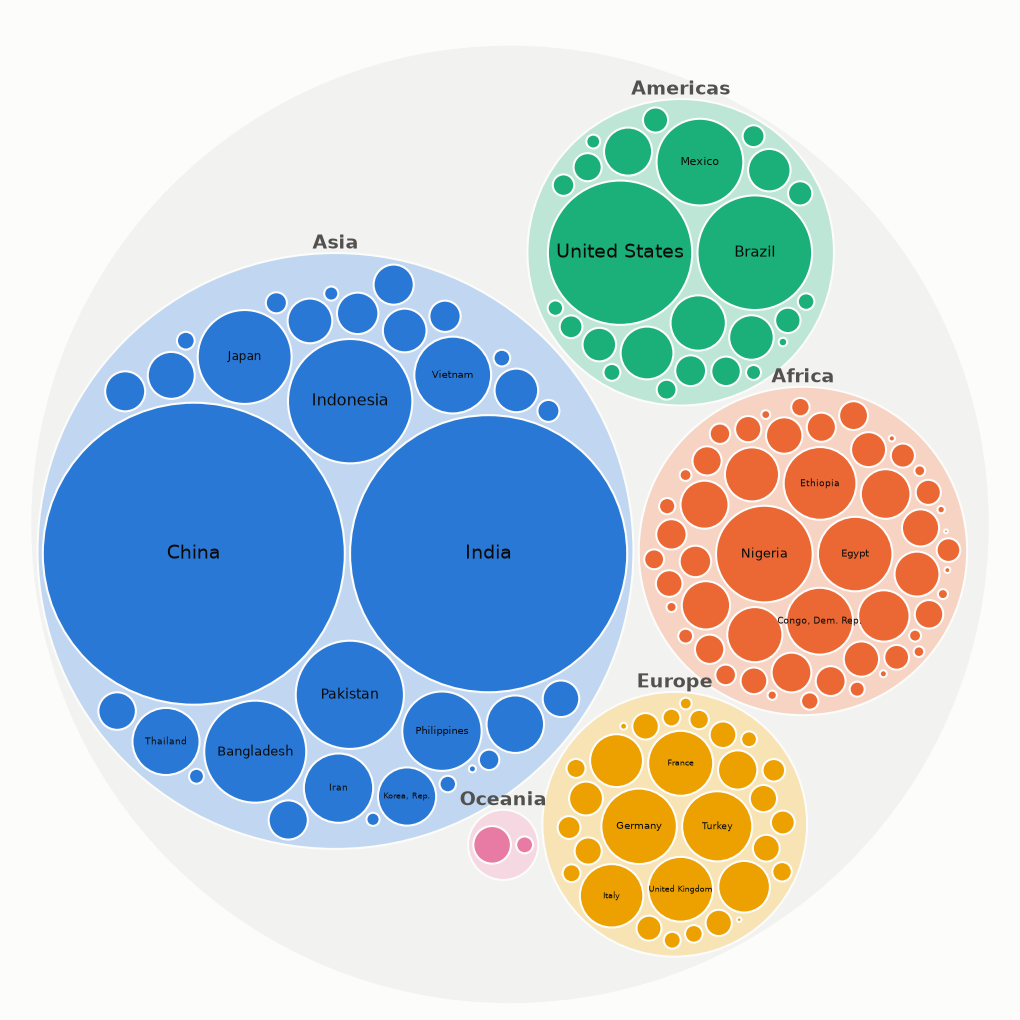

In [13]:
pc.circular_treemap(g07, ['continent', 'country'], 'pop')

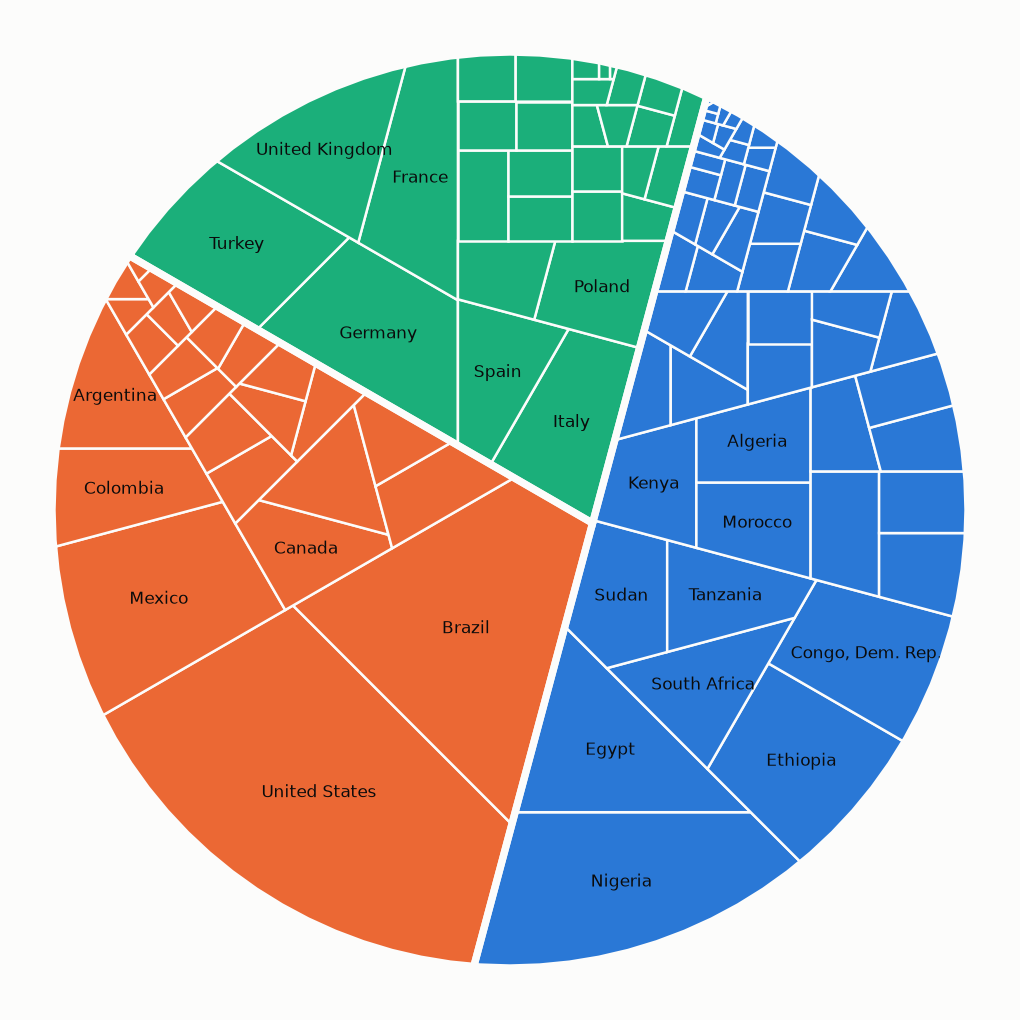

In [14]:
pc.convex_treemap(g07[g07.continent.isin(['Europe', 'Africa', 'Americas'])], ['continent', 'country'], 'pop')

In [15]:
pc.sunburst(titanic.assign(n=1), ['class', 'sex', 'alive'], 'n', backend='plotly')

<Chart kind='sunburst' backend='plotly' theme='pychartist'>

cluster
2    21
1    19
Name: count, dtype: int64


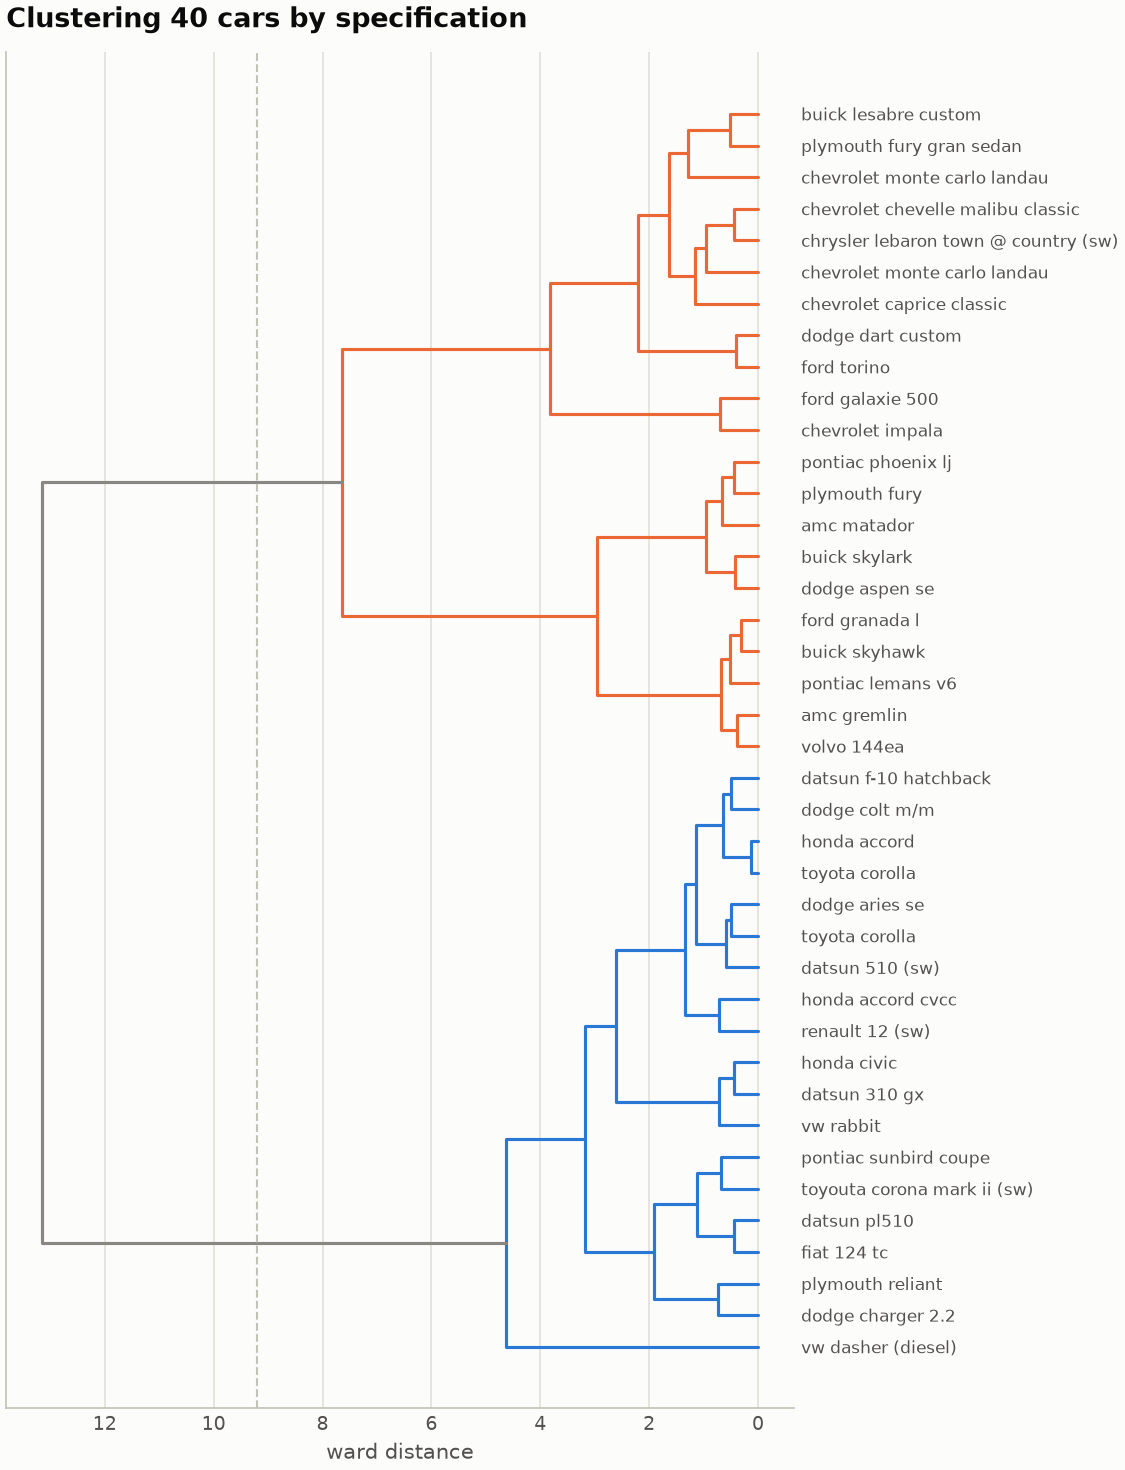

In [16]:
c = pc.examples.demo('dendrogram')
print(c.meta['clusters'].value_counts())
c

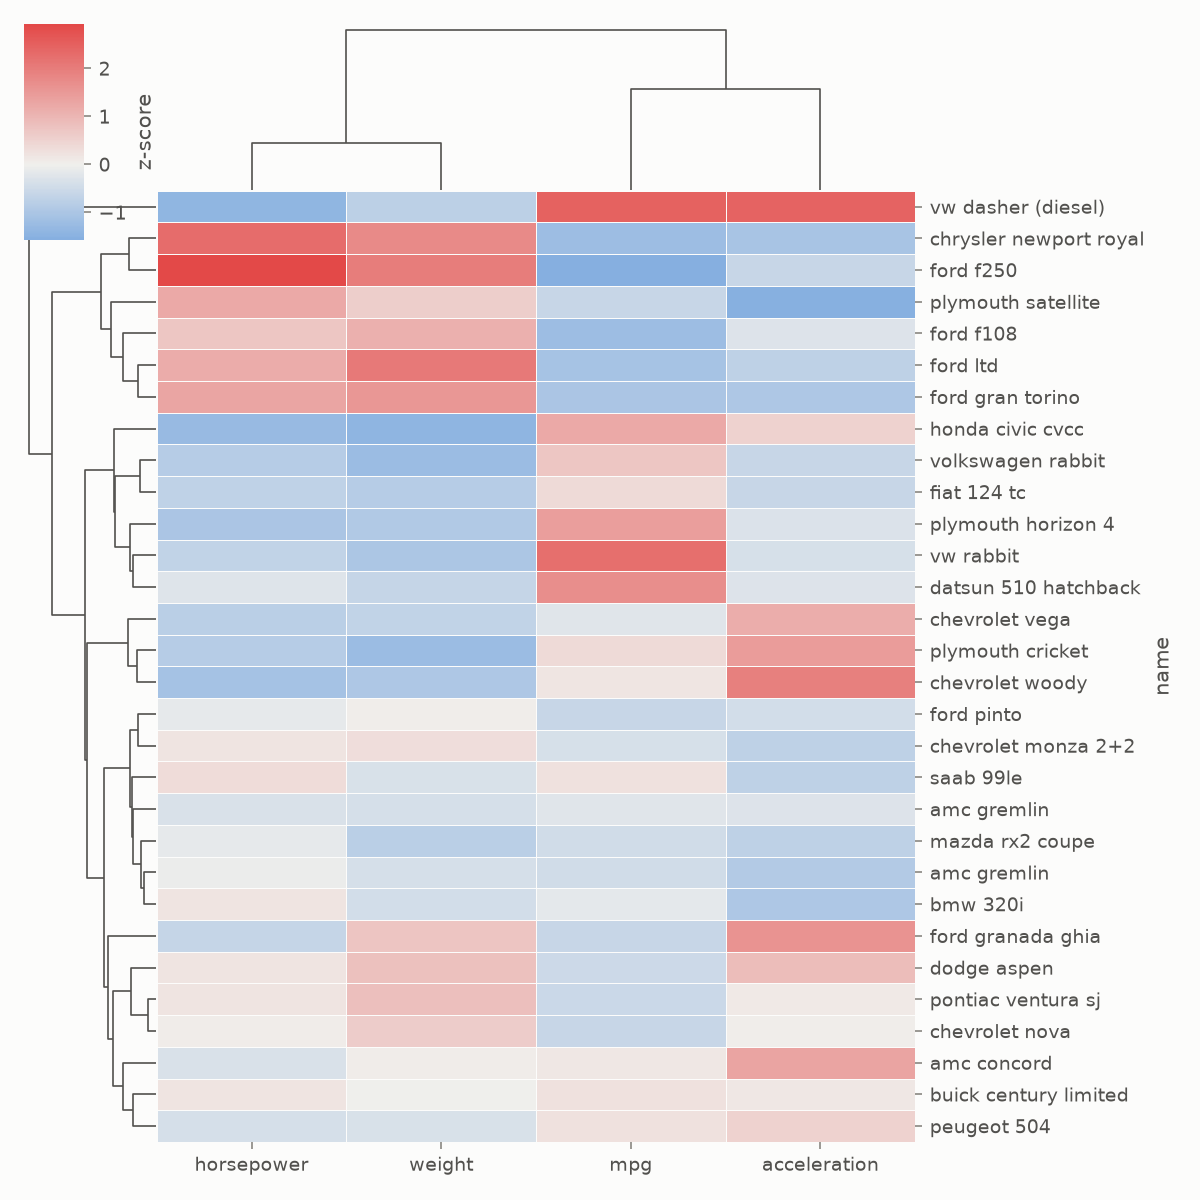

In [17]:
pc.cluster_map(pc.datasets.load('mpg').dropna().sample(30, random_state=2)[['name', 'mpg', 'horsepower', 'weight', 'acceleration']], 'name')

## Sets

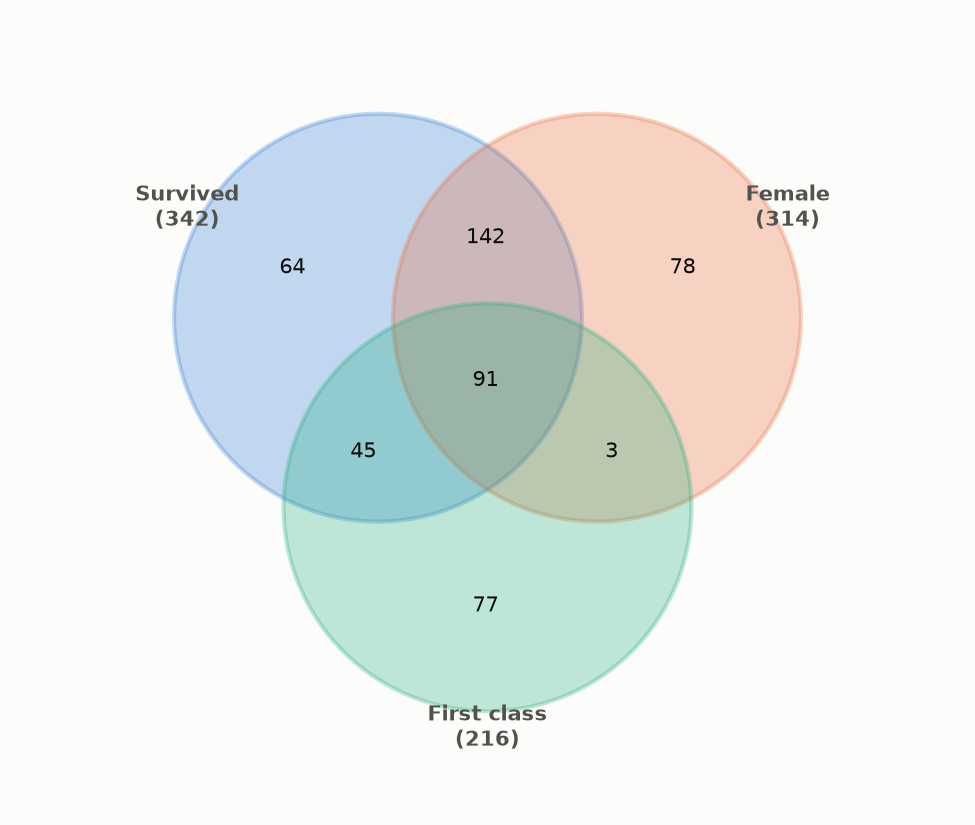

In [18]:
sets = {'Survived': set(titanic.index[titanic.survived == 1]),
        'Female': set(titanic.index[titanic.sex == 'female']),
        'First class': set(titanic.index[titanic.pclass == 1])}
pc.venn(sets)

In [19]:
pc.euler(sets, backend='plotly', title='Area-proportional (Euler)')

<Chart kind='euler' backend='plotly' theme='pychartist', meta=['regions']>

## Single KPIs and pipelines

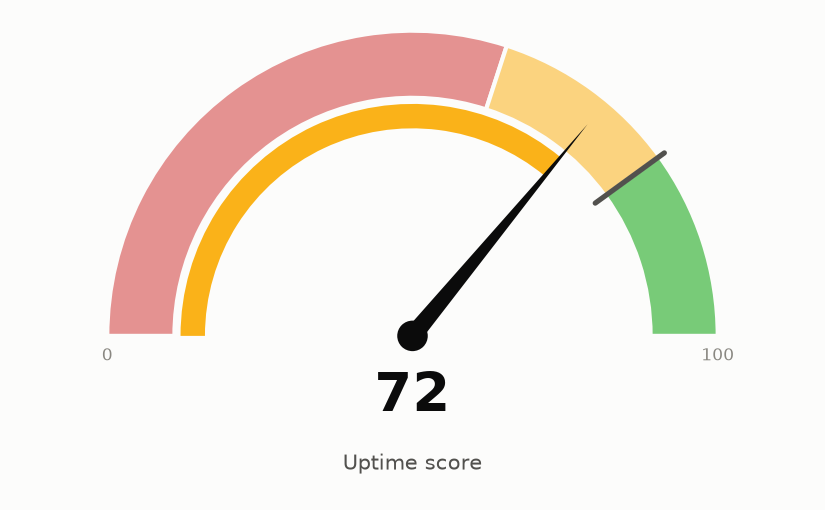

In [20]:
pc.gauge(72, label='Uptime score', target=80, bands=[(60, 'critical'), (80, 'warning'), (100, 'good')])

In [21]:
pc.examples.demo('funnel', backend='plotly')

<Chart kind='funnel' backend='plotly' theme='pychartist'>